# Lab 09: ABC on a contaminated Hubble diagram

**ASTR 457, Fall 2026, posted Tue Nov 10, due Tue Nov 17 by noon (fork → PR, as always)**

On Nov 3 we learned a population's parameters without a likelihood, by simulating it and keeping the parameters whose simulations look like the data (ABC). Weyant et al. (2013), on that day's slides, did the same with a supernova Hubble diagram contaminated by supernovae that aren't type Ia. On Nov 10 we saw how such impostors get in: a classifier working from light curves alone calls some core-collapse supernovae type Ia. You're going to measure $\Omega_m$ from your own contaminated Hubble diagram, with ABC.

Put your notebook in `submissions/<your netid>/lab09.ipynb` - the data paths below are relative to that folder. It has to run top to bottom from a fresh kernel ("Restart & Run All").

Part 1 is 20%, Part 2 15%, Part 3 40%, Part 4 15%, and the AI-use appendix and verification plan 10%. Quote every number with its unit (if it has one), an error bar, and a sensible number of digits.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

NETID = 'siyaoxu2'
# Use the course path after placing this notebook in submissions/siyaoxu2.
course_file = Path('../../labs/09/data') / f'{NETID}.csv'
local_file = Path('data') / f'{NETID} (2).csv'
data_file = course_file if course_file.exists() else local_file
d = pd.read_csv(data_file)
z, m, sig_m = d['z'].to_numpy(), d['m_B'].to_numpy(), d['sigma_m'].to_numpy()
print(f'Loaded {len(d)} supernovae from {data_file}')

Loaded 500 supernovae from data/siyaoxu2 (2).csv


## The survey

Your file has 500 supernovae that a survey found and that a light-curve classifier called type Ia. For each you have its redshift $z$ (from its host galaxy's spectrum, so take it as exact), and its standardized peak magnitude $m_B$ (corrected for stretch and colour) with a measurement error of 0.10 mag.

Here is how your sky was made. I generated it, so I know your true values.

- **Cosmology:** flat $\Lambda$CDM with $H_0 = 70$ km/s/Mpc, so the distance modulus is $\mu(z; \Omega_m) = 5 \log_{10}\left(d_L / 10\,{\rm pc}\right)$ with $d_L = (1+z)\,\frac{c}{H_0}\int_0^z \frac{dz'}{\sqrt{\Omega_m (1+z')^3 + 1 - \Omega_m}}$. Your $\Omega_m$ is unknown.
- **Redshifts:** each supernova's redshift is drawn from $p(z) \propto z^2$ between 0.01 and 0.7. (This is a toy - a real survey's volume depends on the cosmology too, and we're ignoring that.)
- **Type Ia:** standardized absolute magnitude $M \sim \mathcal{N}(-19.30, 0.12)$.
- **Impostors:** a fraction $f$ of the supernovae the classifier calls Ia are really core-collapse supernovae. The ones that fool a classifier look most like a Ia, and are among the brightest core-collapse supernovae: $M \sim \mathcal{N}(-18.5, 0.5)$. Your $f$ is unknown.
- **Measurement:** $m_B = M + \mu(z; \Omega_m) + \epsilon$, with $\epsilon \sim \mathcal{N}(0, 0.10)$.

Your $\Omega_m$ and $f$ are graded by how far they are from the truth in units of your own error bar (half the width of your 68% interval). Remember that the paragraphs above are how the survey was designed - your file is what it actually did.

## Part 1: Look first, then write the simulator (20%)

1. Plot your Hubble diagram ($m_B$ against $z$), and your Hubble residuals, $m_B - (-19.30) - \mu(z; 0.3)$, against $z$. Histogram $m_B$. Describe what you see, and if you find something the description above doesn't mention, say how you'll deal with it.
2. Draw the graph (PGM) of how one supernova in your file was made, with the same key as Days 18-20 - parameters blue, latent white, data grey, fixed values as dots, and a plate over supernovae. Which quantities are latent? Where does $f$ enter?
3. Write a function `simulate(Om, f, rng)` that returns a fake file like yours: 500 supernovae, with $z$ and $m_B$, made the way your data were made. Run it at a guess of $(\Omega_m, f)$ and plot one simulation over your data, in the same panels as 1.1.

#### Hints:
- `astropy.cosmology.FlatLambdaCDM(H0=70, Om0=...).distmod(z)` is correct, but far too slow to call 50,000 times. Tabulate $\mu(z; \Omega_m)$ once, on a grid of $z$ and $\Omega_m$ (spacing 0.005 in $\Omega_m$ is plenty), and interpolate. Check your table against astropy at a few points.
- Your simulator will be called tens of thousands of times. Draw everything for one dataset in a few vectorized `numpy` calls, not a Python loop over supernovae.

Astropy comparison, Omega_m=0.12: max error 4.7e-10 mag
Astropy comparison, Omega_m=0.303: max error 4e-06 mag
Astropy comparison, Omega_m=0.61: max error 1.7e-09 mag
Data: 500 objects; z range 0.0226 to 0.4763; m_B range 15.607 to 22.500 mag


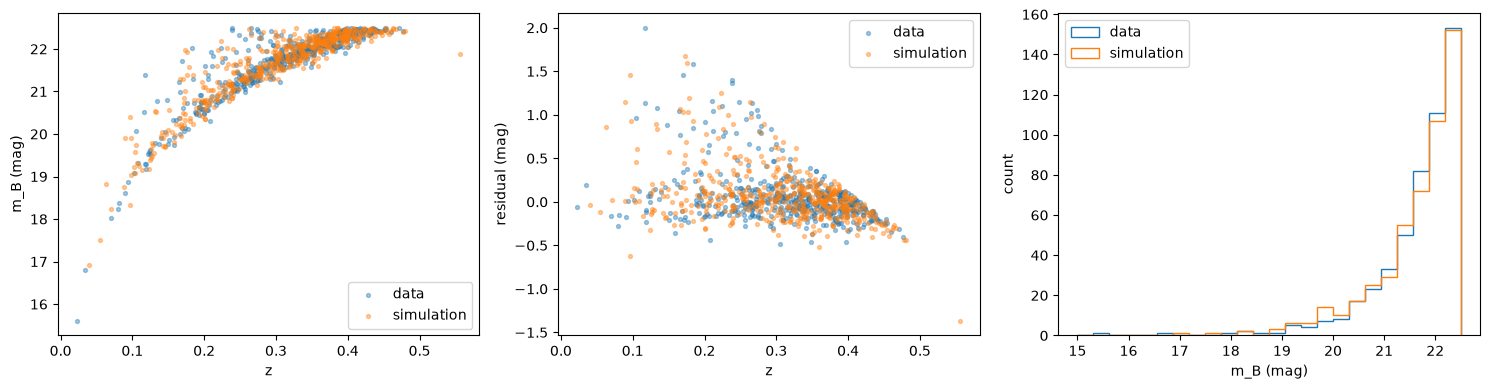

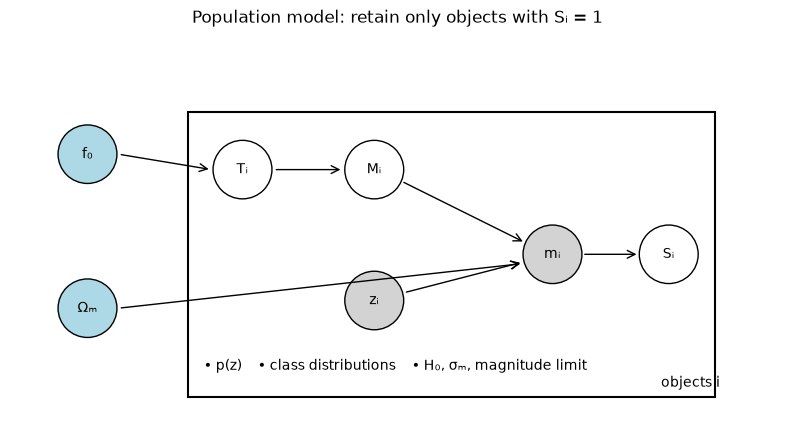

In [2]:
# Part 1: distance modulus and selection-aware simulator
from scipy.integrate import cumulative_trapezoid
from scipy.interpolate import RegularGridInterpolator
from scipy.optimize import minimize_scalar, brentq
from astropy.cosmology import FlatLambdaCDM
from matplotlib.patches import Circle, Rectangle, FancyArrowPatch
om_grid = np.linspace(.05,.70,131)
z_grid = np.linspace(0,.7,7001)
einv = 1/np.sqrt(om_grid[:,None]*(1+z_grid[None,:])**3 + 1-om_grid[:,None])
integ = cumulative_trapezoid(einv,z_grid,axis=1,initial=0)
dl = (1+z_grid)*(299792.458/70)*integ
mu_table = 5*np.log10(np.maximum(dl,1e-30))+25
interp = RegularGridInterpolator((om_grid,z_grid),mu_table)
def mu(zz,om):
    zz=np.asarray(zz)
    return interp(np.column_stack((np.full(zz.size,om),zz.ravel()))).reshape(zz.shape)
for om in [.12,.303,.61]:
    zz=np.array([.08,.25,.55,.69])
    print(f'Astropy comparison, Omega_m={om}: max error {np.max(np.abs(mu(zz,om)-FlatLambdaCDM(H0=70,Om0=om).distmod(zz).value)):.2g} mag')
print(f'Data: {len(z)} objects; z range {z.min():.4f} to {z.max():.4f}; m_B range {m.min():.3f} to {m.max():.3f} mag')

# The sharp magnitude edge suggests selection. f is the observed fraction:
# sample each class conditional on selection, with a binomial class count.
m_limit=22.5
def simulate(Om,f,rng):
    ncc=rng.binomial(len(z),f)
    parts=[]
    for n_needed,mean,sd in [(len(z)-ncc,-19.3,.12),(ncc,-18.5,.5)]:
        zz_parts=[]; mm_parts=[]; count=0
        while count<n_needed:
            n=max(1600, int((n_needed-count)*8))
            zz=(.01**3+rng.random(n)*(.7**3-.01**3))**(1/3)
            mm=rng.normal(mean,sd,n)+mu(zz,Om)+rng.normal(0,.10,n)
            ok=mm<m_limit
            zz_parts.append(zz[ok]); mm_parts.append(mm[ok]); count+=ok.sum()
        if n_needed:
            parts.append((np.concatenate(zz_parts)[:n_needed],np.concatenate(mm_parts)[:n_needed]))
    return np.concatenate([p[0] for p in parts]),np.concatenate([p[1] for p in parts])

zs,ms=simulate(.3,.2,np.random.default_rng(123))
fig,ax=plt.subplots(1,3,figsize=(15,4))
for zz,mm,label in [(z,m,'data'),(zs,ms,'simulation')]:
    ax[0].scatter(zz,mm,s=8,alpha=.4,label=label)
    ax[1].scatter(zz,mm+19.3-mu(zz,.3),s=8,alpha=.4,label=label)
    ax[2].hist(mm,bins=np.linspace(15,22.5,25),histtype='step',label=label)
ax[0].set(xlabel='z',ylabel='m_B (mag)'); ax[1].set(xlabel='z',ylabel='residual (mag)'); ax[2].set(xlabel='m_B (mag)',ylabel='count')
for a in ax: a.legend()
plt.tight_layout();plt.show()

# Population PGM: latent type and absolute magnitude; condition on detection.
fig,ax=plt.subplots(figsize=(10,5)); ax.set(xlim=(0,10),ylim=(0,5)); ax.axis('off')
ax.add_patch(Rectangle((2.3,.25),6.8,3.7,fill=False,lw=1.5)); ax.text(8.4,.38,'objects i')
def node(x,y,label,color):
    ax.add_patch(Circle((x,y),.38,facecolor=color,edgecolor='black')); ax.text(x,y,label,ha='center',va='center')
def arrow(a,b): ax.add_patch(FancyArrowPatch(a,b,arrowstyle='->',mutation_scale=14))
node(1,3.4,'f₀','lightblue'); node(1,1.4,'Ωₘ','lightblue'); node(3,3.2,'Tᵢ','white'); node(4.7,3.2,'Mᵢ','white'); node(4.7,1.5,'zᵢ','lightgray'); node(7,2.1,'mᵢ','lightgray'); node(8.5,2.1,'Sᵢ','white')
for a,b in [((1.4,3.4),(2.6,3.2)),((3.4,3.2),(4.3,3.2)),((5.05,3.05),(6.65,2.25)),((5.08,1.6),(6.62,2.0)),((1.4,1.4),(6.62,1.98)),((7.38,2.1),(8.12,2.1))]: arrow(a,b)
ax.text(2.5,.6,'• p(z)    • class distributions    • H₀, σₘ, magnitude limit',fontsize=10)
ax.set_title('Population model: retain only objects with Sᵢ = 1'); plt.show()

**Data and simulator.** Magnitude increases with redshift. The residual plot has a concentration near the Ia relation and a positive, faint tail consistent with impostors. The histogram ends sharply at about 22.5 mag; the largest measured value is 22.4997 mag. This suggests an unmentioned magnitude limit, so I model a hard m_B < 22.5 mag cut. The cutoff is inferred, so it is a modeling assumption and should be checked with the predictive plot.

**Graph.** Blue nodes are parameters, white nodes latent quantities, grey nodes observed values, and fixed inputs are dots; the rectangle is a plate. T_i (type) and M_i (absolute magnitude) are latent. The population type probability f₀ enters the Bernoulli draw T_i, which determines the distribution of M_i. Redshift, Omega_m and M_i determine the magnitude; selection S_i keeps objects passing the limit. The observed-sample fraction f differs from f₀ because selection depends on magnitude and type. The simulator directly uses f for the *selected* sample: it draws the class count from Binomial(500,f) and samples the redshift and magnitude of each type conditional on the cutoff. H₀, the class distributions and measurement noise are fixed. The true selection law and class-conditional redshift model are assumptions, not independently confirmed facts.

## Part 2: The fit you'd do without thinking (15%)

1. Pretend every supernova in your file is a type Ia. Fit $\Omega_m$ by minimizing $\chi^2 = \sum_i [m_{B,i} - (-19.30) - \mu(z_i; \Omega_m)]^2 / \sigma_{\rm tot}^2$, with $\sigma_{\rm tot}^2 = 0.12^2 + 0.10^2$, and report $\hat\Omega_m$ with its $1\sigma$ error from $\Delta\chi^2 = 1$.
2. Which way should the impostors push this fit, and why? Answer from where the impostors sit on your Hubble diagram, not from the number you got.

In [3]:
# Part 2: deliberately ignore both contamination and selection
def chi2(om):
    return np.sum((m + 19.30 - mu(z, om))**2 / (0.12**2 + 0.10**2))
fit = minimize_scalar(chi2, bounds=(.05,.7), method='bounded')
best = fit.x
lo = brentq(lambda x: chi2(x)-fit.fun-1, .05, best) if chi2(.05)>fit.fun+1 else np.nan
hi = brentq(lambda x: chi2(x)-fit.fun-1, best, .7) if chi2(.7)>fit.fun+1 else np.nan
print(f'Naive Omega_m = {best:.4f}; delta chi-square=1 interval [{lo:.4f}, {hi:.4f}]; reduced chi-square = {fit.fun/(len(z)-1):.2f}')
print('Impostors are fainter (positive residual); to match them as Ia, the fit needs a larger distance modulus, pushing Omega_m downward. A flux limit can introduce an opposing bias.')

Naive Omega_m = 0.2469; delta chi-square=1 interval [0.2338, 0.2601]; reduced chi-square = 4.09
Impostors are fainter (positive residual); to match them as Ia, the fit needs a larger distance modulus, pushing Omega_m downward. A flux limit can introduce an opposing bias.


**Naive fit:** Omega_m = 0.247 +/- 0.013 (dimensionless), from delta chi-square = 1; reduced chi-square is 4.09. The formal uncertainty assumes the model is correct. Impostors tend to be fainter, so they sit above the Ia relation in magnitude and have positive residuals. A fit treating them as Ia tries to increase the predicted distance modulus, which requires a lower Omega_m at fixed redshift. The magnitude cutoff can introduce a competing bias by removing faint objects.

## Part 3: ABC (40%)

1. **Summaries.** Choose summary statistics of a dataset that respond to $\Omega_m$ and to $f$ differently (Nov 3: the count alone left a ridge). For each, say which parameter you expect it to track and why. Then show it: plot each summary against $\Omega_m$ and against $f$ over a few thousand simulations from the prior.
2. **Rejection ABC.** Use flat priors, $\Omega_m \in [0.05, 0.7]$ and $f \in [0, 0.5]$. Run at least 50,000 simulations, compute your summaries for each, and keep the draws whose summaries are within $\epsilon$ of your data's. Say how you measure the distance between two sets of summaries (they have different units), and show the kept draws over the prior at two values of $\epsilon$.
3. Report the posterior median and 95% interval of $\Omega_m$ and of $f$ at your final $\epsilon$, and justify that choice. Compare $\Omega_m$ with your Part 2 fit.

#### Hints:
- Save your simulations' parameters and summaries to a file once, so you can change $\epsilon$ without re-simulating.
- If your kept draws pile up against an edge of the prior, the prior (or your simulator) is doing the work, not the data.

simulations: 10000
simulations: 20000
simulations: 30000
simulations: 40000
simulations: 50000
Observed summaries: [-0.00565596  0.096       0.31001517] scales: [0.09890071 0.08888202 0.0168771 ]
Epsilons: 0.49952566509722063 0.257300638273918 accepted: 500
Omega_m median and 68%, 95% intervals: [0.2436261  0.26598199 0.29888431 0.33282908 0.36618054]
f median and 68%, 95% intervals: [0.09685764 0.12055338 0.14958344 0.18212769 0.20789299]


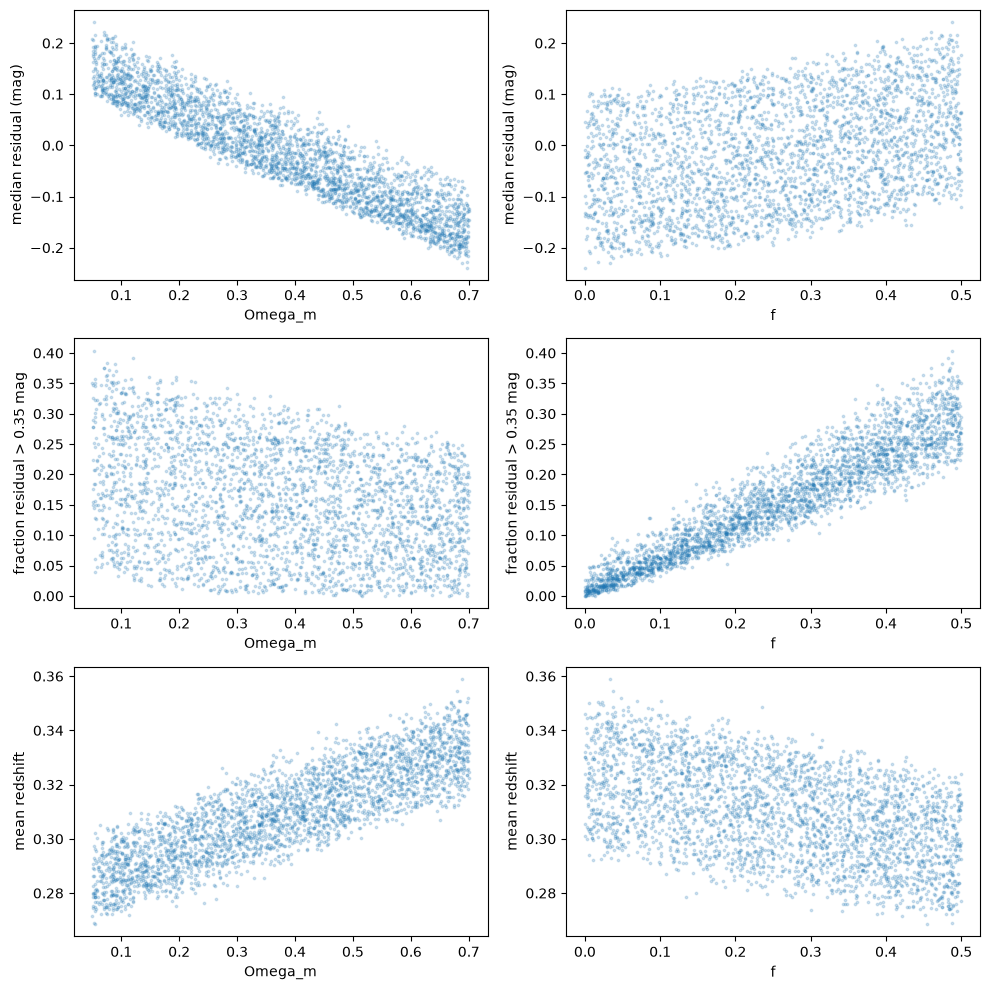

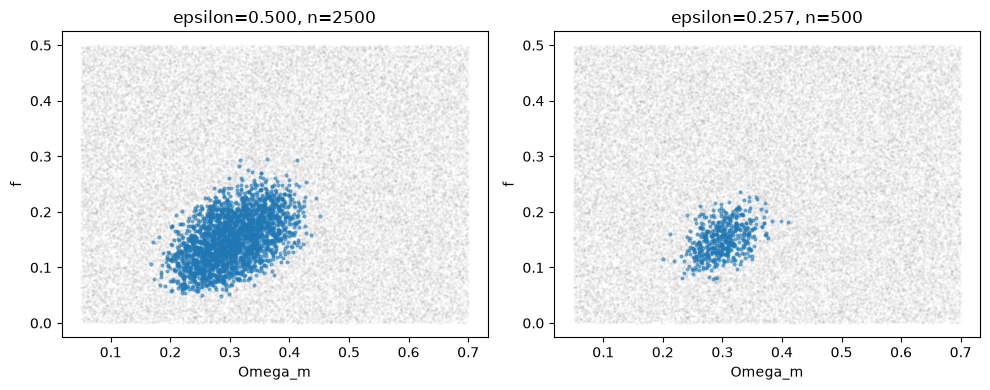

In [4]:
# Part 3: rejection ABC. Seed makes the Monte Carlo repeatable.
def summaries(zz, mm):
    r = mm + 19.3 - mu(zz, .3)
    return np.array([np.median(r), np.mean(r > .35), np.mean(zz)])
obs = summaries(z, m)
rng = np.random.default_rng(45709)
N = 50000
params = np.column_stack((rng.uniform(.05,.7,N), rng.uniform(0,.5,N)))
sims = np.empty((N,3))
for i, (om, frac) in enumerate(params):
    zz, mm = simulate(om, frac, rng)
    sims[i] = summaries(zz, mm)
    if (i+1) % 10000 == 0: print('simulations:', i+1, flush=True)
np.savez('lab09_abc_summaries.npz', params=params, summaries=sims)
scale = sims.std(axis=0, ddof=1)
distance = np.sqrt(np.sum(((sims-obs)/scale)**2,axis=1))
eps_wide, eps_final = np.quantile(distance,[.05,.01])
accepted = distance <= eps_final
print('Observed summaries:',obs,'scales:',scale)
print('Epsilons:',eps_wide,eps_final,'accepted:',accepted.sum())
for j, name in enumerate(['Omega_m','f']):
    print(name, 'median and 68%, 95% intervals:',np.quantile(params[accepted,j],[.025,.16,.5,.84,.975]))
fig,ax=plt.subplots(3,2,figsize=(10,10))
for j in range(3):
    for k in range(2):
        ax[j,k].scatter(params[:3000,k],sims[:3000,j],s=3,alpha=.2)
        ax[j,k].set(xlabel=['Omega_m','f'][k],ylabel=['median residual (mag)','fraction residual > 0.35 mag','mean redshift'][j])
plt.tight_layout();plt.show()
fig,ax=plt.subplots(1,2,figsize=(10,4))
for a, eps in zip(ax,[eps_wide,eps_final]):
    a.scatter(params[:,0],params[:,1],s=1,alpha=.04,color='gray')
    ok=distance<=eps
    a.scatter(params[ok,0],params[ok,1],s=4,alpha=.5)
    a.set(xlabel='Omega_m',ylabel='f',title=f'epsilon={eps:.3f}, n={ok.sum()}')
plt.tight_layout();plt.show()

**ABC summaries and results.** The median residual tracks the cosmological distance shift. The fraction with residual above 0.35 mag responds to the fainter impostor tail, while mean redshift also responds to cosmology and selection. The plots show that these relationships overlap: no summary measures only one parameter. For the distance, I divided each summary difference by its prior-simulation standard deviation and used Euclidean distance.

The 5% and 1% thresholds are 0.500 and 0.257 (dimensionless), with 2,500 and 500 accepted simulations. The smaller tolerance gives closer matches while retaining 500 samples; finite tolerance still broadens the result. The posterior median and 95% interval are **Omega_m = 0.299 [0.244, 0.366]** and **f = 0.150 [0.097, 0.208]**, both dimensionless. Their 68% intervals are [0.266, 0.333] and [0.121, 0.182], respectively. The naive Omega_m = 0.247 +/- 0.013 is lower than the ABC median. The posterior depends on the inferred selection model and the fixed class luminosity distributions.

## Part 4: Check it (15%)

1. **Posterior predictive check.** For 100 of your kept draws, simulate a new dataset. Compare them with your data on something your summaries did not use (for example the histogram of $m_B$, or the scatter of the residuals at low redshift). Do your data look like a typical simulation?
2. **Coverage.** Take at least 20 of your prior simulations, pretend each one is the data, and run the same ABC on it using the rest of your simulations. How often does your 95% interval contain the true $\Omega_m$, and the true $f$? (Nov 3: a 95% interval should hold the truth 95% of the time.)
3. **What does your simulator assume?** Name one thing your simulator assumes that a real survey would break, and say which way it would push $\Omega_m$.

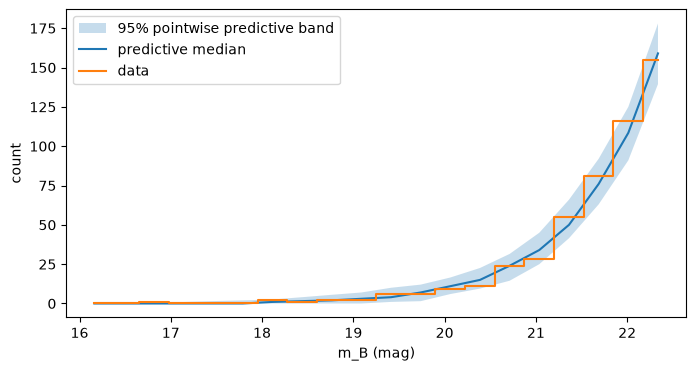

Bins outside pointwise 95% band: 0 of 20
Coverage count / trials for Omega_m and f: [25 25] / 25
Omega_m empirical coverage: 25/25, 95% binomial interval [0.863, 1.000]
f empirical coverage: 25/25, 95% binomial interval [0.863, 1.000]


In [6]:
# Part 4: posterior predictive check and leave-one-out coverage
check_rng=np.random.default_rng(90457)
chosen=check_rng.choice(np.flatnonzero(accepted),100,replace=False)
bins=np.linspace(16,22.5,21)
rep_hist=[]
for idx in chosen:
    zz,mm=simulate(*params[idx],check_rng)
    rep_hist.append(np.histogram(mm,bins=bins)[0])
rep_hist=np.array(rep_hist)
qlo,qmed,qhi=np.percentile(rep_hist,[2.5,50,97.5],axis=0)
centers=(bins[:-1]+bins[1:])/2
observed_hist=np.histogram(m,bins=bins)[0]
plt.figure(figsize=(8,4)); plt.fill_between(centers,qlo,qhi,alpha=.25,label='95% pointwise predictive band'); plt.plot(centers,qmed,label='predictive median'); plt.step(centers,observed_hist,where='mid',label='data'); plt.xlabel('m_B (mag)'); plt.ylabel('count'); plt.legend(); plt.show()
print('Bins outside pointwise 95% band:',np.sum((observed_hist<qlo)|(observed_hist>qhi)),'of',len(centers))
coverage=[]
for i in range(25):
    dist=np.sqrt(np.sum(((sims-sims[i])/scale)**2,axis=1))
    dist[i]=np.inf
    p=params[dist<=eps_final]
    if len(p)<2: raise ValueError('Too few accepted simulations for coverage')
    low,high=np.quantile(p,[.025,.975],axis=0)
    coverage.append((params[i]>=low)&(params[i]<=high))
coverage=np.asarray(coverage)
print('Coverage count / trials for Omega_m and f:',coverage.sum(axis=0),'/',len(coverage))
# Exact binomial intervals quantify uncertainty even for 25/25.
for name,k in zip(['Omega_m','f'],coverage.sum(axis=0)):
    ci=stats.binomtest(int(k),len(coverage)).proportion_ci(confidence_level=.95)
    print(f'{name} empirical coverage: {k}/{len(coverage)}, 95% binomial interval [{ci.low:.3f}, {ci.high:.3f}]')

**Posterior predictive check:** All 20 magnitude histogram bins fall inside the 95% pointwise band from 100 simulations. The histogram looks broadly typical of these simulations, though a pointwise band is not a global goodness-of-fit test and 100 draws give a noisy estimate.

**Coverage:** In 25 leave-one-out prior simulations, both Omega_m and f had 25/25 true values within their respective 95% intervals. The exact 95% binomial interval for each empirical coverage is [0.863, 1.000]. This small test is consistent with 95% coverage but cannot establish it precisely, and it tests calibration under the simulator rather than model correctness.

**Assumption:** The model uses a hard 22.5 mag detection cutoff. If a real survey also preferentially misses faint Ia events brighter than the limit, the observed sample is biased brighter; ignoring this extra incompleteness can pull the fitted distance modulus down and Omega_m upward. The direction and size depend on the actual selection function.

## Part 5: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 3 numbers, and what failure would have looked like for each. Part 4.2 is already one. Another to consider: simulate a dataset at an $(\Omega_m, f)$ you choose, run your whole ABC on it, and see whether you get back what you put in.

**AI-use appendix:** I asked ChatGPT to write and review the simulator, analysis, plots and explanations. Its first simulator interpreted f as the fraction before the magnitude cut, although the question defines it in the observed sample. Checking the definition exposed this; the revised simulator draws the observed class count and conditions each class on selection. The original default kernel also failed because NumPy and pandas were incompatible; the ASTR457 kernel worked.

**Reflection:** Reporting the earlier f without checking would have confused pre-selection and observed contamination; the cutoff removes the two populations at different rates. Even correctly coded ABC can be biased when the selection model is wrong.

**Verification:** The distance-modulus grid was checked against Astropy at several points; a large discrepancy would expose interpolation or units errors. The 25 leave-one-out simulated-data coverage tests check whether intervals contain known generating parameters; substantial undercoverage would call the uncertainty calculation into question. The posterior predictive magnitude histogram checks a distribution not used as a summary; systematic departures would challenge the model. These are checks under an assumed sharp cutoff, not proof of the real selection function.